# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("/content/drive/MyDrive/vdui/unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [3]:

# TODO 1: one 1080p RGB frame, in MB
width = 1920
height = 1080
channels = 3
bits_per_channel = 8

bytes_per_frame = width * height * channels * (bits_per_channel / 8)
frame_mb = bytes_per_frame / (1024 ** 2)

# TODO 2: frames per camera per day at 30 fps
fps = 30
seconds_per_day = 24 * 60 * 60
frames_per_day = fps * seconds_per_day

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
cameras = 400
fleet_bytes = bytes_per_frame * frames_per_day * cameras
fleet_tb = fleet_bytes / (1024 ** 4)

# TODO 4: 640x360 and 10 fps
small_width = 640
small_height = 360
small_fps = 10

small_bytes_per_frame = small_width * small_height * channels
small_frames_per_day = small_fps * seconds_per_day

fleet_tb_small = (
    small_bytes_per_frame * small_frames_per_day * cameras
) / (1024 ** 4)

pct_pixels_remaining = (
    small_width * small_height / (width * height)
) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day")
print(f"Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining: {pct_pixels_remaining:.2f}%")


One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day
Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_ After downsampling to 640 × 360 only 11.11% of the pixels of each frame are left, so the fine spatial detail is gone for good. For example the characters on a number plate or a person's face would become a few blurry pixels. Interpolation (Slide 13) can only guess new pixels from the neighbouring ones when we scale the image back up, it cannot bring back the real detail. On the temporal side, going from 30 fps to 10 fps means we keep one frame every 0.1 s instead of every 0.033 s. A very quick action, like someone throwing something, starting to run or a car brushing against another one, can happen completely between two stored frames. Also, with bigger gaps between frames it becomes harder to match the same object from one frame to the next (the correspondence problem, Slides 36–37), so tracking who did what gets less reliable.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

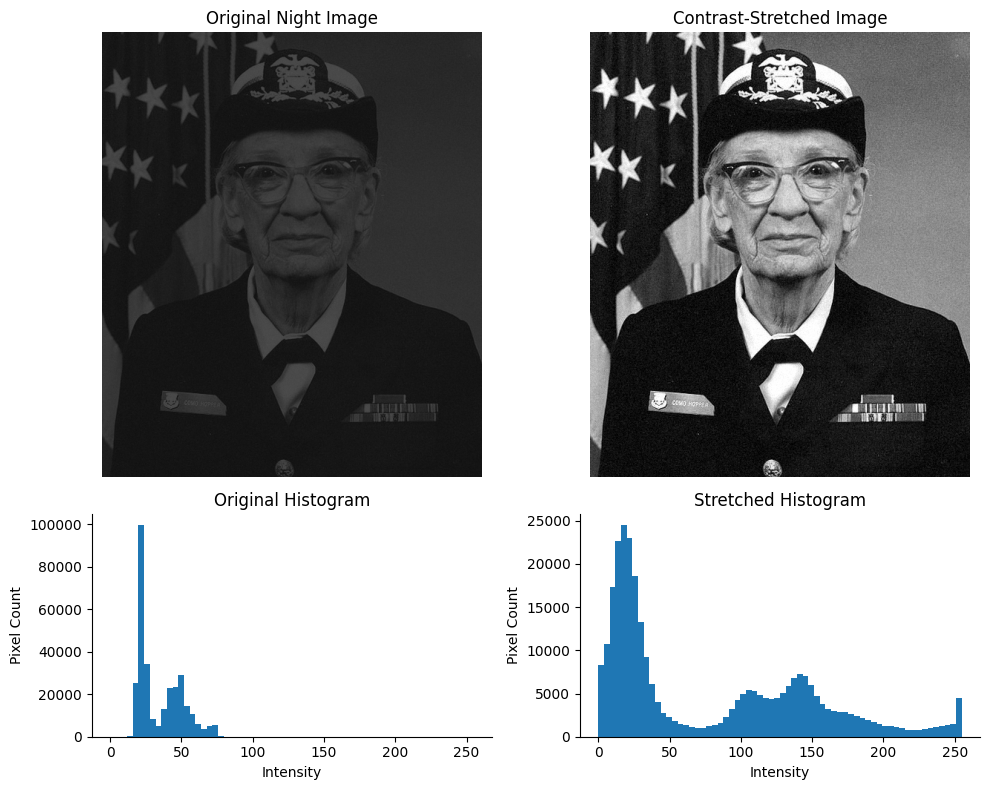

Contrast before: 0.609 -> after: 1.000


In [4]:

def michelson(lmax, lmin):
    denominator = lmax + lmin
    if denominator == 0:
        return 0
    return (lmax - lmin) / denominator


# TODO 2: robust Michelson contrast
p1 = np.percentile(night_still, 1)
p99 = np.percentile(night_still, 99)

c_before = michelson(p99, p1)

# TODO 3: contrast stretching
stretched = (night_still - p1) * 255 / (p99 - p1)
stretched = np.clip(stretched, 0, 255)

# Contrast after stretching, using robust percentiles
s1 = np.percentile(stretched, 1)
s99 = np.percentile(stretched, 99)
c_after = michelson(s99, s1)

# TODO 1 and 4: images and histograms
fig, axes = plt.subplots(
    2, 2, figsize=(10, 8),
    gridspec_kw={"height_ratios": [2, 1]}
)

axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Night Image")
axes[0, 0].axis("off")

axes[1, 0].hist(
    night_still.ravel(), bins=64, range=(0, 255)
)
axes[1, 0].set_title("Original Histogram")
axes[1, 0].set_xlabel("Intensity")
axes[1, 0].set_ylabel("Pixel Count")

axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast-Stretched Image")
axes[0, 1].axis("off")

axes[1, 1].hist(
    stretched.ravel(), bins=64, range=(0, 255)
)
axes[1, 1].set_title("Stretched Histogram")
axes[1, 1].set_xlabel("Intensity")
axes[1, 1].set_ylabel("Pixel Count")

plt.tight_layout()
plt.show()

print(f"Contrast before: {c_before:.3f} -> after: {c_after:.3f}")


**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_ The histogram of the night image is bunched up at the dark end. Almost all the pixels lie between about 13 and 79 out of 255 (1st percentile ≈ 17.8, 99th percentile ≈ 73.4, median ≈ 26.5), with a long thin tail towards the brighter values. So in the lecture's vocabulary it is a dark (under-exposed) histogram that is also narrow, which means low contrast. The brightest part of the range is never used. Contrast stretching just maps 17.8 → 0 and 73.4 → 255 in a straight line, so the same pixel ordering is spread over the whole display range. Our eyes can now see the differences between neighbouring grey levels that were too small to notice before, but no new information was added. The Michelson contrast went from 0.609 to 1.000, and this is partly because I measured it with the same percentiles I stretched to, so it is 1 by construction. A histogram only counts how many pixels have each intensity and says nothing about where they are. If we shuffled all the pixels of the photo randomly we would get noise with exactly the same histogram, so the histogram can tell us the image is murky but never what is in it (Same Histogram ≠ Same Image).

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing periods:
  68.7 s to 78.1 s
Running periods:
  78.6 s to 86.0 s
Car in frame: 20.0 s to 32.0 s
Person in frame: 40.0 s to 86.0 s
Audio event: frame 2250, t = 75.00 s
Lighting event: frame 3000, t = 100.00 s


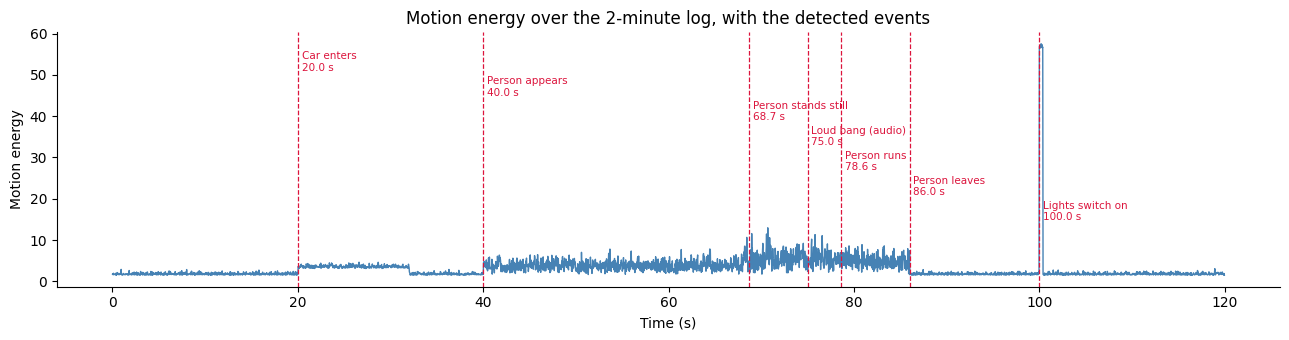

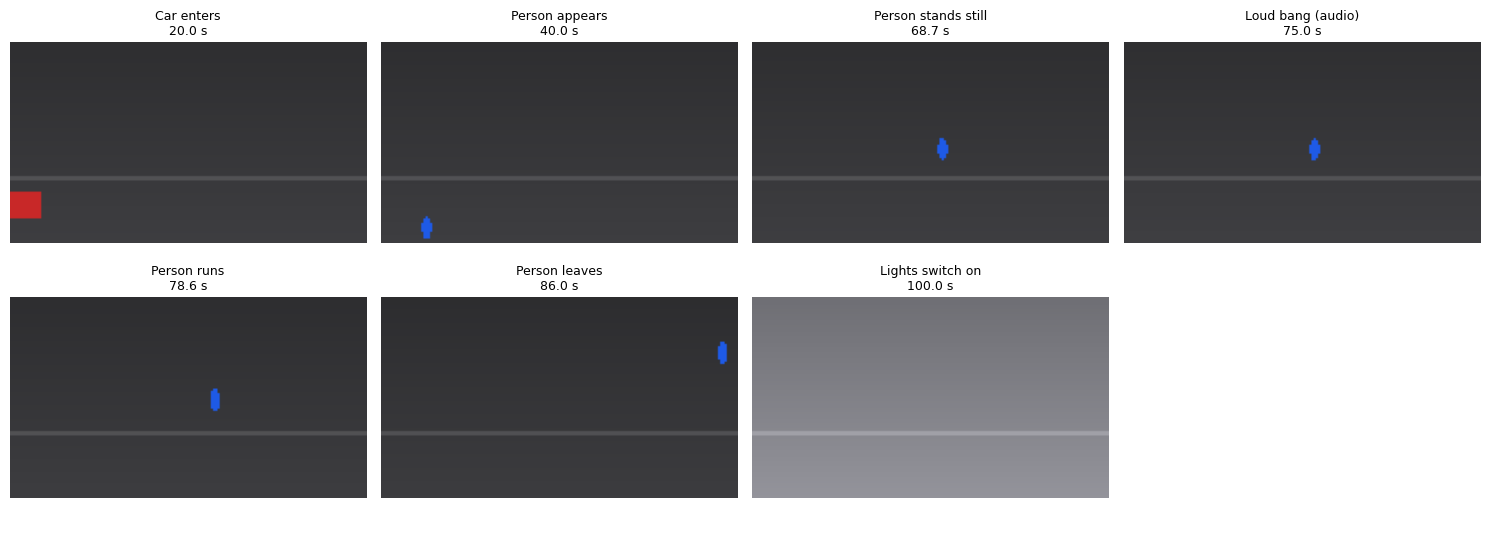

In [5]:
# TODO 1: person speed (px/s)
# displacement over a 1-second window (FPS frames) so tracking jitter averages out
time_s = cctv["time_s"].to_numpy()
x = cctv["person_x"]
y = cctv["person_y"]

dx = x.diff(FPS)
dy = y.diff(FPS)
speed = np.sqrt(dx**2 + dy**2).to_numpy(copy=True)   # copy=True so we are allowed to edit it
speed[(x.isna() | y.isna()).to_numpy()] = np.nan      # no person in frame -> no speed

# TODO 2: standing / running time ranges
def find_ranges(mask, min_len_s=1.0, merge_gap_s=1.0):
    """Turn a True/False array into (start, end) frame ranges.
    Small gaps are merged and very short ranges dropped, otherwise jitter
    splits one long stand into dozens of tiny pieces."""
    mask = np.nan_to_num(np.asarray(mask, dtype=float)).astype(bool)
    edges = np.diff(np.r_[0, mask.astype(int), 0])
    starts = list(np.where(edges == 1)[0])
    ends = list(np.where(edges == -1)[0] - 1)
    merged = []
    for s, e in zip(starts, ends):
        if merged and (s - merged[-1][1]) / FPS <= merge_gap_s:
            merged[-1][1] = e
        else:
            merged.append([s, e])
    return [(s, e) for s, e in merged if (e - s) / FPS >= min_len_s]

with np.errstate(invalid="ignore"):
    standing_ranges = find_ranges(speed < 3)
    running_ranges = find_ranges(speed > 25)

print("Standing periods:")
for s, e in standing_ranges:
    print(f"  {time_s[s]:.1f} s to {time_s[e]:.1f} s")
print("Running periods:")
for s, e in running_ranges:
    print(f"  {time_s[s]:.1f} s to {time_s[e]:.1f} s")

# extra context events: when the car and the person first appear / leave
car_idx = np.where(cctv["car_x"].notna())[0]
person_idx = np.where(x.notna())[0]
print(f"Car in frame: {time_s[car_idx[0]]:.1f} s to {time_s[car_idx[-1]]:.1f} s")
print(f"Person in frame: {time_s[person_idx[0]]:.1f} s to {time_s[person_idx[-1]]:.1f} s")

# TODO 3: audio and lighting event indices
audio_db = cctv["audio_level_db"].to_numpy()
brightness = cctv["mean_brightness"].to_numpy()
motion = cctv["motion_energy"].to_numpy()

audio_event_idx = int(np.where(audio_db > -20)[0][0])               # first frame above -20 dB
lighting_event_idx = int(np.where(np.diff(brightness) > 40)[0][0] + 1)  # +1 because diff is shifted by one

print(f"Audio event: frame {audio_event_idx}, t = {time_s[audio_event_idx]:.2f} s")
print(f"Lighting event: frame {lighting_event_idx}, t = {time_s[lighting_event_idx]:.2f} s")

# collect every event in one dictionary (label -> frame index)
events = {
    "Car enters": int(car_idx[0]),
    "Person appears": int(person_idx[0]),
    "Person stands still": standing_ranges[-1][0],
    "Loud bang (audio)": audio_event_idx,
    "Person runs": running_ranges[0][0],
    "Person leaves": int(person_idx[-1]),
    "Lights switch on": lighting_event_idx,
}
events = dict(sorted(events.items(), key=lambda kv: kv[1]))

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(time_s, motion, color="steelblue", lw=1)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Motion energy")
ax.set_title("Motion energy over the 2-minute log, with the detected events")
top = motion.max()
for k, (label, idx) in enumerate(events.items()):
    ax.axvline(time_s[idx], color="crimson", ls="--", lw=0.9)
    ax.text(time_s[idx] + 0.4, top * (0.97 - 0.105 * k),
            f"{label}\n{time_s[idx]:.1f} s", fontsize=7.5, color="crimson", va="top")
plt.tight_layout()
plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(2, 4, figsize=(15, 5.5))
for ax, (label, idx) in zip(axes.ravel(), events.items()):
    ax.imshow(render_frame(cctv.iloc[idx]))
    ax.set_title(f"{label}\n{time_s[idx]:.1f} s", fontsize=9)
    ax.axis("off")
for ax in axes.ravel()[len(events):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_ Uniform keyframes would be taken at 0, 20, 40, 60, 80, 100 and 120 s, so they ignore what is happening in the video. The events that matter most would very likely be missed. The bang at 75 s only lasts about 0.4 s (the audio is above −20 dB from 75.0 s to about 75.4 s), and the moment the person starts running at 78.6 s also falls between the 60 s and 80 s frames. The 68.7 s moment when the person stops and starts standing, and the 86 s moment when they leave, would be missed as well. Only the events that happen to land near a multiple of 20 s would be caught by luck. The lights switching on at 100 s is a short spike in motion energy, so it also depends on luck. The approach I used instead is content-based keyframe extraction (Slide 40): the frames are chosen by detecting changes in the data (motion, audio, brightness) rather than by the clock. This works much better when the activity is sparse, like here where most of the 2 minutes is an empty car park.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

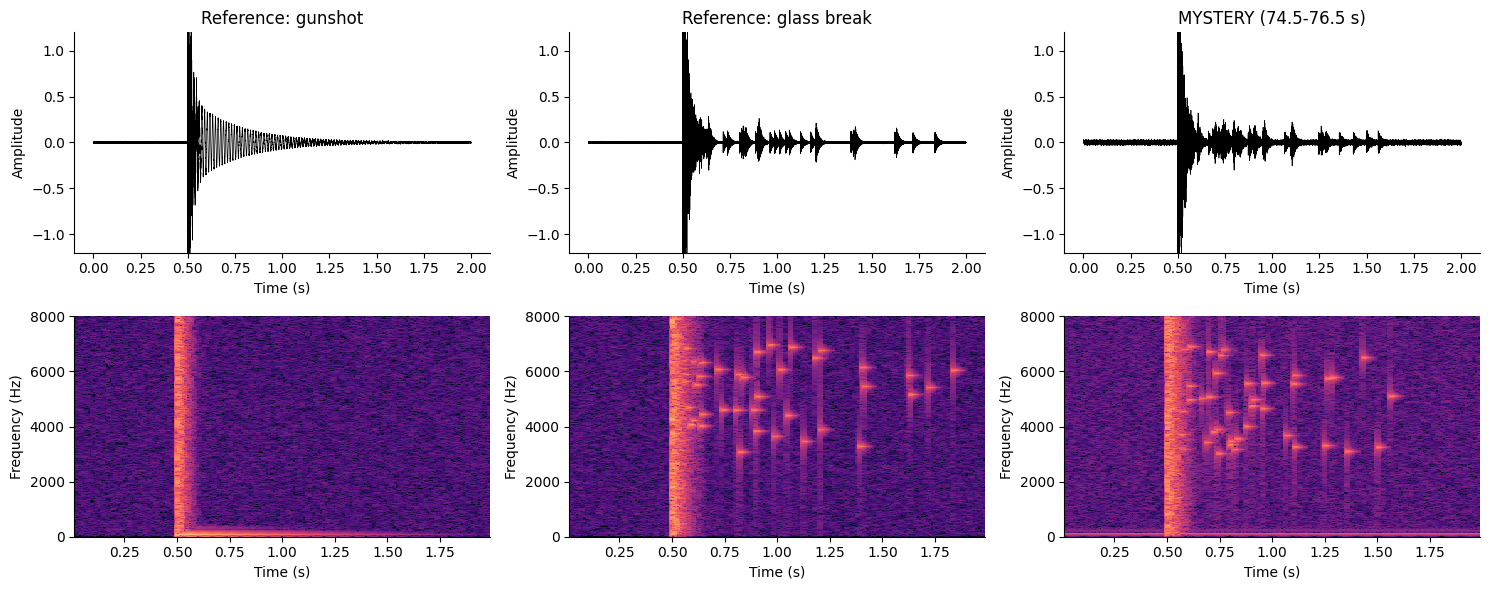

{'Reference: gunshot': 0.003, 'Reference: glass break': 0.989, 'MYSTERY (74.5-76.5 s)': 0.873}
Verdict: the mystery sound has 87% of its energy above 3 kHz after the impact, which matches the glass break reference.


In [6]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
t_clip = np.arange(int(2.0 * FS)) / FS          # every clip is 2 s long
for k, (name, sig) in enumerate(clips.items()):
    # top row: waveform
    axes[0, k].plot(t_clip, sig, lw=0.5, color="k")
    axes[0, k].set_title(name)
    axes[0, k].set_xlabel("Time (s)")
    axes[0, k].set_ylabel("Amplitude")
    axes[0, k].set_ylim(-1.2, 1.2)

    # bottom row: spectrogram in dB
    f, tt, Sxx = signal.spectrogram(sig, fs=FS, nperseg=512, noverlap=384)
    Sdb = 10 * np.log10(Sxx + 1e-12)
    axes[1, k].pcolormesh(tt, f, Sdb, shading="auto", cmap="magma", vmin=-110, vmax=-20)
    axes[1, k].set_ylim(0, 8000)
    axes[1, k].set_xlabel("Time (s)")
    axes[1, k].set_ylabel("Frequency (Hz)")

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, sig in clips.items():
    f, tt, Sxx = signal.spectrogram(sig, fs=FS, nperseg=512, noverlap=384)
    window_cols = (tt >= 0.5 + 0.2) & (tt <= 0.5 + 1.2)   # 0.7 s to 1.7 s in clip time
    band = Sxx[:, window_cols]
    hf_fraction[name] = band[f > 3000].sum() / band.sum()

print({k: round(float(v), 3) for k, v in hf_fraction.items()})

# TODO 4: verdict
closest = min(["Reference: gunshot", "Reference: glass break"],
              key=lambda n: abs(hf_fraction[n] - hf_fraction["MYSTERY (74.5-76.5 s)"]))
print(f"Verdict: the mystery sound has {hf_fraction['MYSTERY (74.5-76.5 s)']:.0%} of its energy above 3 kHz "
      f"after the impact, which matches the {closest.replace('Reference: ', '')} reference.")


**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_ No, not confidently. In all three waveforms there is a sudden loud spike at 0.5 s, a quick decay and then almost silence, so they all look alike. The glass break is slightly more spread out after the impact, but the small tinkles are tiny compared to the first spike and are hard to see. The waveform shows *when* something loud happened but not *what kind* of sound it is. The spectrogram adds the frequency, because it has three dimensions: time on the x-axis, frequency on the y-axis, and magnitude (energy in dB) shown by the colour. The pattern that decided my verdict was the scattered high-frequency specks. After the vertical stripe from the impact, the mystery clip has many small bright dots between roughly 3 and 7 kHz over the next second, which is what the glass reference shows. The gunshot reference instead has the vertical stripe plus a low horizontal band (the boom near 70 Hz) and nothing after it. The numbers agree: the fraction of energy above 3 kHz is about 0.3% for the gunshot, 98.9% for the glass break and 87.3% for the mystery sound, so it is glass breaking.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

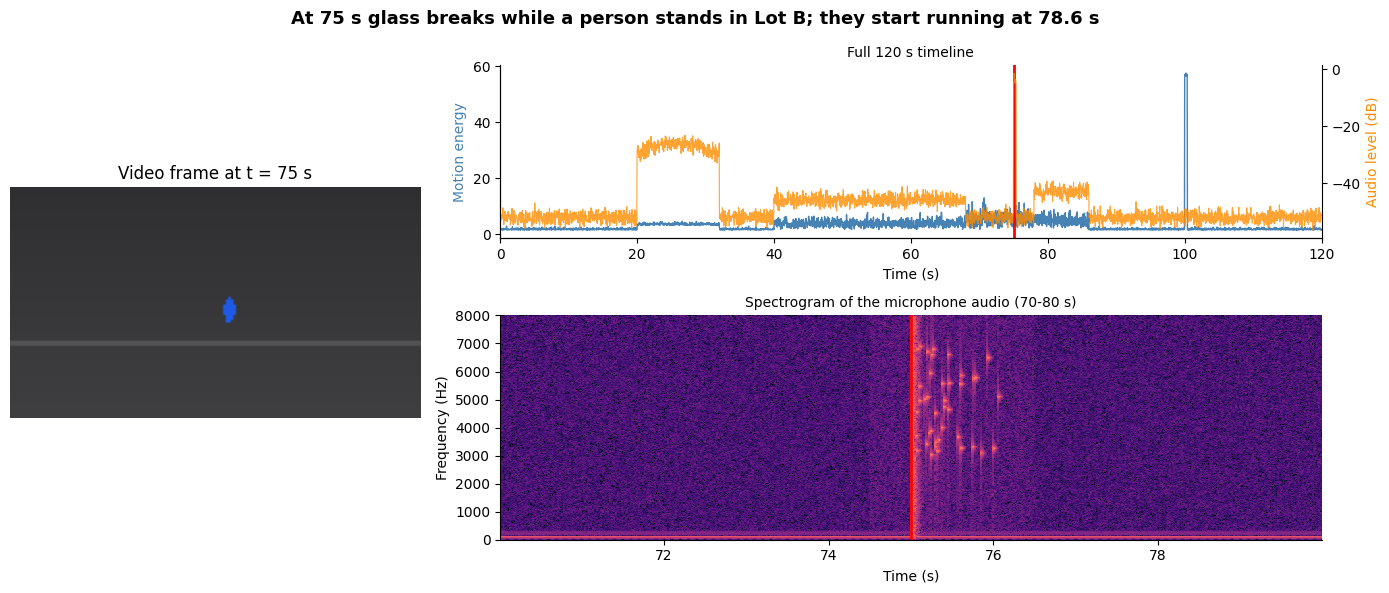

In [7]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
sel_idx = int(round(t_sel * FPS))
time_s = cctv["time_s"].to_numpy()

# 1) video frame at 75 s (left, spans both rows)
ax_img = fig.add_subplot(gs[:, 0])
ax_img.imshow(render_frame(cctv.iloc[sel_idx]))
ax_img.set_title(f"Video frame at t = {t_sel:.0f} s")
ax_img.axis("off")

# 2) motion + audio timeline (top right), audio on a second y-axis
ax_t = fig.add_subplot(gs[0, 1])
ax_t.plot(time_s, cctv["motion_energy"], color="steelblue", lw=1, label="Motion energy")
ax_t.set_ylabel("Motion energy", color="steelblue")
ax_t.set_xlim(0, 120)
ax_t2 = ax_t.twinx()
ax_t2.plot(time_s, cctv["audio_level_db"], color="darkorange", lw=0.8, alpha=0.8, label="Audio level (dB)")
ax_t2.set_ylabel("Audio level (dB)", color="darkorange")
ax_t2.spines["right"].set_visible(True)
ax_t.axvline(t_sel, color="red", lw=2)
ax_t.set_title("Full 120 s timeline", fontsize=10)
ax_t.set_xlabel("Time (s)")

# 3) spectrogram of 70-80 s audio (bottom right)
ax_s = fig.add_subplot(gs[1, 1])
f, tt, Sxx = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
ax_s.pcolormesh(70 + tt, f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma", vmin=-110, vmax=-20)
ax_s.set_ylim(0, 8000)
ax_s.axvline(t_sel, color="red", lw=2)
ax_s.set_xlabel("Time (s)")
ax_s.set_ylabel("Frequency (Hz)")
ax_s.set_title("Spectrogram of the microphone audio (70-80 s)", fontsize=10)

# 4) conclusion-style title
fig.suptitle("At 75 s glass breaks while a person stands in Lot B; they start running at 78.6 s",
             fontsize=13, fontweight="bold")

plt.tight_layout(); plt.show()


**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_ If the audio were 2 s late compared with the video, the bang would be placed at 77 s on the common time axis instead of 75 s. The cause and effect would then look wrong: the frame at 75 s would be paired with silence, and the reaction time of the person would be reported as about 1.6 s (bang at 77 s, running at 78.6 s) instead of about 3.6 s. Someone might even think the person broke the glass because they started running right after it. The mistake would be visible in the spectrogram panel (and the audio line in the timeline panel), because the red marker at 75 s would no longer sit on the bright vertical stripe of the impact but 2 s before it, while the video frame and the motion curve stay where they were. This is also why the briefing should stay simple (three linked panels with one shared marker): more panels would just add to the information overload.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_ At 75 s a person who had been standing still in Lot B since 68.7 s caused a loud impact that the audio matches to breaking glass, not a gunshot, and they ran away from 78.6 s until they left the frame at 86 s, after which the lights came on at 100 s. I would open the briefing with the synchronized view (video frame + motion/audio timeline + spectrogram, all with the same 75 s marker), because it gives the overview first and then lets every claim be checked in two modalities at the same time. Inside it the spectrogram is the key part, since its time × frequency × magnitude view is what separated glass (87% of the energy above 3 kHz) from a gunshot (0.3%), and that decides which response to send. For storage, uncompressed 1080p at 30 fps for 400 cameras would be about 5,866 TB per day and even 360p at 10 fps is about 217 TB per day, so I recommend recording at low resolution and frame rate when nothing is happening and switching to full quality around motion or audio events (content-based, as in Task 3). The one thing it must not sacrifice is the audio at its full 16 kHz sampling rate, because the high-frequency content above 3 kHz was the only evidence that separated glass from gunshot, along with a good frame rate around the event itself.